In [1]:
import os
import glob
import math
from typing import Callable, Any
from dataclasses import dataclass

import cv2
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.stats import norm

In [2]:
class ImageConverter:
    def __init__(self, L_MIN: float = 0.1, L_MAX: float = 300.0):
        self.M = np.array([
            [0.4124564, 0.3575761, 0.1804375],
            [0.2126729, 0.7151522, 0.0721750],
            [0.0193339, 0.1191920, 0.9503041]
        ], dtype=np.float64)
        self.M_inv = np.array([
            [ 3.1338561, -1.6168667, -0.4906146],
            [-0.9787684,  1.9161415,  0.0334540],
            [ 0.0719453, -0.2289914,  1.4052427]
        ], dtype=np.float64)

        self.L_MAX = float(L_MAX)
        self.L_MIN = float(L_MIN)
        self.coord_white = np.array([0.3127, 0.3290, 0.3583], dtype=np.float64)
        self.eps = 1e-10

    def sRGB_Companding(self, linear_image: np.ndarray) -> np.ndarray:
        linear = np.clip(np.asarray(linear_image, dtype=np.float64), 0.0, 1.0)
        encoded = np.where(
            linear <= 0.0031308,
            linear * 12.92,
            1.055 * (linear ** (1.0 / 2.4)) - 0.055
        )
        return encoded

    def Inverse_sRGB_Companding(self, image: np.ndarray) -> np.ndarray:
        img = np.asarray(image, dtype=np.float64)
        linear = np.where(
            img <= 0.04045,
            img / 12.92,
            ((img + 0.055) / 1.055) ** 2.4
        )
        return linear

    def Linear_RGB_to_XYZ(self, image: np.ndarray) -> np.ndarray:
        XYZ_image = image.reshape(-1, 3)
        return (XYZ_image @ self.M.T).reshape(image.shape)

    def XYZ_to_xyzL(self, XYZ_image: np.ndarray) -> np.ndarray:
        sum_xyz = XYZ_image.sum(keepdims=True, axis=-1)
        xyz = XYZ_image / (sum_xyz + self.eps)

        is_black = (sum_xyz < self.eps).squeeze(-1)
        if np.any(is_black):
            xyz[is_black] = self.coord_white

        Y = XYZ_image[..., 1]
        L_norm = np.clip(Y, 0.0, 1.0)
        L_physical = self.L_MIN + L_norm * (self.L_MAX - self.L_MIN)
        L_physical = np.expand_dims(L_physical, axis=-1)

        xyzL = np.concatenate([xyz, L_physical], axis=-1)
        return xyzL

    def RGB_to_xyzL(self, image: np.ndarray) -> np.ndarray:
        norm_img = np.asarray(image, dtype=np.float64) / 255.0
        linRGBimg = self.Inverse_sRGB_Companding(norm_img)
        XYZ_image = self.Linear_RGB_to_XYZ(linRGBimg)
        xyzL_image = self.XYZ_to_xyzL(XYZ_image)
        return xyzL_image

    def L_to_gray(self, L: np.ndarray | float) -> np.ndarray | np.uint8:
        Y_lin = (L - self.L_MIN) / (self.L_MAX - self.L_MIN)
        Y_lin = np.clip(Y_lin, 0.0, 1.0)
        V = self.sRGB_Companding(Y_lin)
        gray_matrix = np.rint(V * 255).astype(np.uint8)
        return gray_matrix

In [3]:
@dataclass
class OptimizationResults:
    La: float
    optimization_history: dict | None = None


class SimkinJNDModel:
    def __init__(
        self,
        L_MIN: float = 0.1,
        L_MAX: float = 300.0,
        screen_diag_inch: float = 16.0,
        screen_width_px: int = 1920,
        screen_height_px: int = 1080,
        distance_m: float = 0.5,
        l_gray: float = 60.0
    ):
        self.L_MIN = float(L_MIN)
        self.L_MAX = float(L_MAX)
        self.L0 = 1e-6

        diag_px = math.sqrt(screen_width_px ** 2 + screen_height_px ** 2)
        self.ppi = diag_px / screen_diag_inch
        pixel_size_m = 0.0254 / self.ppi

        self.phi_screen = pixel_size_m / distance_m
        self.phi = self.phi_screen

        self.screen_width_px = screen_width_px
        self.screen_height_px = screen_height_px
        self.l_gray = float(l_gray)
        self.La = self.l_gray
        self.bounds = np.empty(0, dtype=np.float64)
        self.len_left = 0

    def _Simkin_A(self, La: float | np.ndarray) -> float | np.ndarray:
        a1 = 4800000.0
        a2 = 7100.0
        a3 = 0.00045
        return 1.0 + np.sqrt(a1 * La) + a2 * La * (1.0 + np.sqrt(a3 * La))

    def _Simkin_l(self, La: float | np.ndarray) -> float | np.ndarray:
        return self.L0 * self._Simkin_A(La)

    def _Simkin_lambda(self, L: np.ndarray | float, La: float | np.ndarray) -> np.ndarray | float:
        xao = 100.0
        return L / (xao * self._Simkin_l(La))

    def _Simkin_LAt(self, lambda_: np.ndarray | float) -> np.ndarray | float:
        b1 = 0.98
        b2 = 0.1
        lambda1 = 0.02
        lambda_arr = np.asarray(lambda_, dtype=np.float64)
        return np.where(lambda_arr <= 1.0, b1 * (lambda_arr + lambda1), lambda_arr ** (1.0 + b2))

    def _Simkin_ro(self, La: float | np.ndarray) -> float | np.ndarray:
        l1 = 10.0
        l2 = 0.000026
        c2 = 0.25
        return (1.0 + l1 / (l2 + La)) ** c2

    def _Simkin_teta(self, phi: float, La: float | np.ndarray) -> float | np.ndarray:
        phi_omin = (1.0 / 60.0) * np.pi / 180.0
        return phi / (phi_omin * self._Simkin_ro(La))

    def _Simkin_S(self, teta: float | np.ndarray) -> float | np.ndarray:
        teta1 = 6.1
        return (teta1 / teta + 1.0) ** 2

    def _simkin_nu(self, La: float | np.ndarray) -> float | np.ndarray:
        safe_la = np.maximum(La, 1e-12)
        nu = 4.1 - 3.4 / (1.0 + np.exp(-0.5 - np.log10(safe_la)))
        return np.clip(nu, 1.0, 4.0)

    def _simkin_T(self, t: float, La: float | np.ndarray) -> float | np.ndarray:
        return t / (0.05 * self._simkin_nu(La))

    def _simkin_C(self, T: float | np.ndarray) -> float | np.ndarray:
        return 1.0 + 1.0 / T

    def _Simkin_fN(self, La: float | np.ndarray, L: np.ndarray | float, LN: float) -> np.ndarray | float:
        sigma_n = 3.0 * LN / self._Simkin_l(La)
        lat_val = self._Simkin_LAt(self._Simkin_lambda(L, La))
        return np.sqrt(1.0 + (sigma_n * sigma_n) / (lat_val * lat_val))

    def _simkin_core(
        self,
        La: float | np.ndarray,
        L: np.ndarray | float,
        phi: float | None = None,
        LN: float = 0.0,
        t: float = 1.0
    ) -> np.ndarray | float:
        curr_phi = self.phi if phi is None else phi
        return (
            self.L0
            * self._Simkin_A(La)
            * self._Simkin_LAt(self._Simkin_lambda(L, La))
            * self._Simkin_S(self._Simkin_teta(curr_phi, La))
            * self._Simkin_fN(La, L, LN)
            * self._simkin_C(self._simkin_T(t, La))
        )

    def _compute_screen_geometry(self, L_patch: np.ndarray, target_width: float | str) -> tuple:
        n_patch = L_patch.size
        h_patch_px, w_patch_px = L_patch.shape

        if target_width == 'full':
            phi = self.phi_screen
            n_total = n_patch
            n_patch_screen = n_patch
            n_bg = 0
        elif target_width == 'orig':
            phi = self.phi_screen
            n_total = self.screen_height_px * self.screen_width_px
            n_patch_screen = n_patch
            n_bg = n_total - n_patch
        else:
            aspect_ratio = h_patch_px / w_patch_px
            target_w_px = int(np.round((float(target_width) / 2.54) * self.ppi))
            target_h_px = int(np.round(target_w_px * aspect_ratio))
            n_total = self.screen_height_px * self.screen_width_px
            n_patch_screen = target_w_px * target_h_px
            n_bg = n_total - n_patch_screen
            scale = target_w_px / w_patch_px
            phi = scale * self.phi_screen

        if n_bg < 0:
            raise ValueError("Размер патча превышает размер экрана")

        return phi, n_total, n_patch_screen, n_bg

    def _get_search_bounds(self, L_patch: np.ndarray, has_background: bool) -> tuple[float, float]:
        la_min = max(float(np.min(L_patch)), self.L_MIN)
        la_max = min(float(np.max(L_patch)), self.L_MAX)
        log_la_min = np.log(la_min)
        log_la_max = np.log(la_max)

        if has_background:
            log_bg = np.log(self.l_gray)
            log_la_min = min(log_la_min, log_bg)
            log_la_max = max(log_la_max, log_bg)

        if log_la_min >= log_la_max:
            log_la_min -= 1e-4
            log_la_max += 1e-4

        return float(log_la_min), float(log_la_max)

    def _build_loss_func(
        self,
        L_patch: np.ndarray,
        n_total: int,
        n_patch_screen: int,
        n_bg: int,
        loss_mode: str
    ) -> Callable[[float], float]:
        has_background = n_bg > 0
        has_patch = n_patch_screen > 0
        patch_weight = (n_patch_screen / L_patch.size) if has_patch else 0.0
        bg_weight = float(n_bg)

        den_patch = self._simkin_core(La=L_patch, L=L_patch) if has_patch else None
        den_bg = self._simkin_core(La=self.l_gray, L=self.l_gray) if has_background else None

        if loss_mode == 'square':
            loss_patch = lambda x: float(np.sum(np.square(np.log(np.maximum(x, 1e-12)))))
            loss_bg = lambda x: float(math.log(max(x, 1e-12)) ** 2)
        elif loss_mode == 'abs':
            loss_patch = lambda x: float(np.sum(np.abs(np.log(np.maximum(x, 1e-12)))))
            loss_bg = lambda x: float(abs(math.log(max(x, 1e-12))))
        else:
            raise ValueError(f"Неизвестный loss_mode: {loss_mode}")

        def objective(log_la: float) -> float:
            curr_la = math.exp(log_la)
            total_loss = 0.0
            if has_patch:
                num_patch = self._simkin_core(La=curr_la, L=L_patch)
                total_loss += patch_weight * loss_patch(num_patch / den_patch)
            if has_background:
                num_bg = float(self._simkin_core(La=curr_la, L=self.l_gray))
                total_loss += bg_weight * loss_bg(num_bg / den_bg)
            return total_loss / n_total

        return objective

    def _run_optimizer(
        self,
        loss_func: Callable[[float], float],
        bounds: tuple[float, float],
        optimizer: str,
        **optimizer_kwargs: Any
    ) -> OptimizationResults:
        if optimizer == 'oscillating_optimizer':
            max_reversals = optimizer_kwargs.get('max_reversals', 4)
            step = optimizer_kwargs.get('step', 0.1)
            step_reduction = optimizer_kwargs.get('step_reduction', 2.0)
            start_la = optimizer_kwargs.get('start_La', math.exp(0.5 * (bounds[0] + bounds[1])))
            max_iters = optimizer_kwargs.get('max_iters', 200)

            curr_la = float(start_la)
            best_la = curr_la
            best_loss = loss_func(math.log(curr_la))
            prev_loss = best_loss

            reversals = 0
            direction = 1
            iterations = 0

            while reversals <= max_reversals and iterations < max_iters:
                iterations += 1
                if direction == 1:
                    next_la = curr_la * (1.0 + step)
                    if next_la > math.exp(bounds[1]):
                        direction = -1
                        reversals += 1
                        step /= step_reduction
                        continue
                else:
                    next_la = curr_la / (1.0 + step)
                    if next_la < math.exp(bounds[0]):
                        direction = 1
                        reversals += 1
                        step /= step_reduction
                        continue

                curr_la = next_la
                curr_loss = loss_func(math.log(curr_la))

                if curr_loss < best_loss:
                    best_loss = curr_loss
                    best_la = curr_la

                if curr_loss > prev_loss:
                    direction *= -1
                    reversals += 1
                    step /= step_reduction

                prev_loss = curr_loss

            self.La = best_la
        else:
            raise ValueError(f"Неизвестный оптимизатор: {optimizer}")

        return OptimizationResults(La=self.La)

    def find_La(
        self,
        L_patch: np.ndarray | float,
        target_width: float | str,
        optimizer: str = 'oscillating_optimizer',
        loss_mode: str = 'square',
        **optimizer_params: Any
    ) -> OptimizationResults:
        if isinstance(L_patch, (int, float)):
            L_patch = np.array([[L_patch]], dtype=np.float64)

        phi, n_total, n_patch_screen, n_bg = self._compute_screen_geometry(L_patch=L_patch, target_width=target_width)
        self.phi = phi
        bounds = self._get_search_bounds(L_patch=L_patch, has_background=(n_bg > 0))

        loss_func = self._build_loss_func(
            L_patch=L_patch,
            n_total=n_total,
            n_patch_screen=n_patch_screen,
            n_bg=n_bg,
            loss_mode=loss_mode
        )

        return self._run_optimizer(
            loss_func=loss_func,
            bounds=bounds,
            optimizer=optimizer,
            **optimizer_params
        )

    def build_level_boundaries(self) -> np.ndarray:
        right_bounds = []
        curr_l = self.La
        while curr_l < self.L_MAX:
            step = float(self._simkin_core(L=curr_l, La=self.La))
            if step <= 0:
                break
            curr_l += step
            right_bounds.append(min(curr_l, self.L_MAX))

        left_bounds = []
        curr_l = self.La
        while curr_l > self.L0:
            step = float(self._simkin_core(L=curr_l, La=self.La))
            if step <= 0:
                break
            curr_l -= step
            left_bounds.append(max(curr_l, self.L0))

        self.len_left = len(left_bounds)
        left_bounds.reverse()
        self.bounds = np.array(left_bounds + [self.La] + right_bounds, dtype=np.float64)
        return self.bounds

    def L_to_k(self, L: np.ndarray | float) -> np.ndarray | int:
        idx = np.searchsorted(self.bounds, L, side='right') - 1
        idx = np.clip(idx, 0, len(self.bounds) - 1)
        return idx - self.len_left

In [4]:
@dataclass(frozen=True)
class AdaptationResult:
    La: float
    loss: float
    success: bool
    iterations: int
    function_evaluations: int
    message: str


class HistogramAdaptationJNDModel:
    def __init__(
        self,
        *,
        exposure_time: float = 1.0,
        angular_size_rad: float = 1e-3,
        detection_probability: float = 0.75,
        absolute_threshold: float = 1e-6,
        luminance_floor: float = 1e-6,
        l_min: float = 0.1,
        l_max: float = 300.0,
        screen_width_px: int = 1920,
        screen_height_px: int = 1080,
        l_gray: float = 60.0
    ) -> None:
        if exposure_time <= 0:
            raise ValueError("exposure_time must be positive")
        if angular_size_rad <= 0:
            raise ValueError("angular_size_rad must be positive")
        if not 0 < detection_probability < 1:
            raise ValueError("detection_probability must be in (0, 1)")
        if absolute_threshold <= 0 or luminance_floor <= 0:
            raise ValueError("thresholds must be positive")

        self.t = float(exposure_time)
        self.phi_d = float(angular_size_rad)
        self.p = float(detection_probability)
        self.L0 = float(absolute_threshold)
        self.luminance_floor = float(luminance_floor)

        self.l_min = float(l_min)
        self.l_max = float(l_max)
        self.screen_width_px = int(screen_width_px)
        self.screen_height_px = int(screen_height_px)
        self.l_gray = float(l_gray)

        self.la = self.l_gray
        self.bounds = np.empty(0, dtype=np.float64)
        self.len_left = 0

    @staticmethod
    def _K(lambd, b1=0.98, b2=0.1, lambd1=2e-2):
        lambd = np.asarray(lambd, dtype=np.float64)
        return np.where(lambd <= 1.0, b1 * (1.0 + lambd1 / lambd), lambd**b2)

    @staticmethod
    def _A(La, a1=4.8e6, a2=7.1e3, a3=4.5e-4):
        return 1.0 + np.sqrt(a1 * La) + a2 * La * (1.0 + np.sqrt(a3 * La))

    def _Lambda(self, lambd):
        return lambd * self._K(lambd)

    @staticmethod
    def _eta(La, L3=1e6, L4=1.0, a4=600.0):
        return 1.0 + L3 / (1.0 + a4 * La * (L4 + La))

    def _C(self, La):
        tau_min = 0.05
        T = self.t / (tau_min * self._eta(La))
        return 1.0 + 1.0 / T

    @staticmethod
    def _func_phi_1(La, c2=0.25, L1=10.0, L2=2.6e-5):
        return (1.0 + L1 / (L2 + La)) ** c2

    def _S(self, La, theta_1=6.1, a_d=2.0, inf_phi_1=1.0):
        phi_0_min = 0.5 * (1.0 / 60.0) * (np.pi / 180.0)
        phi_0 = self._func_phi_1(La) * phi_0_min / inf_phi_1
        return (theta_1 * phi_0 / self.phi_d + 1.0) ** a_d

    def _l(self, La):
        return self.L0 * self._A(La)

    def _P(self, p_ref=0.75):
        return abs(norm.ppf(self.p) / norm.ppf(p_ref))

    def D(self, L, La):
        L = np.maximum(np.asarray(L, dtype=np.float64), self.luminance_floor)
        La = np.maximum(np.asarray(La, dtype=np.float64), self.luminance_floor)
        lambd = L / (1e2 * self._l(La))
        return self.L0 * self._A(La) * self._C(La) * self._Lambda(lambd) * self._S(La) * self._P()

    def prepare_histogram(
        self,
        luminance,
        probability,
    ) -> tuple[np.ndarray, np.ndarray]:
        L = np.asarray(luminance, dtype=np.float64).reshape(-1)
        p = np.asarray(probability, dtype=np.float64).reshape(-1)

        if L.size == 0 or L.size != p.size:
            raise ValueError("luminance and probability must have equal non-zero length")
        if not np.all(np.isfinite(L)) or not np.all(np.isfinite(p)):
            raise ValueError("histogram arrays must contain only finite values")
        if np.any(L < 0):
            raise ValueError("luminance values cannot be negative")
        if np.any(p < 0):
            raise ValueError("probabilities cannot be negative")
        if not np.any(p > 0):
            raise ValueError("at least one probability must be positive")

        L = np.maximum(L, self.luminance_floor)
        keep = p > 0
        L, p = L[keep], p[keep]

        unique_L, inverse = np.unique(L, return_inverse=True)
        merged_p = np.zeros(unique_L.size, dtype=np.float64)
        np.add.at(merged_p, inverse, p)
        merged_p /= merged_p.sum()
        return unique_L, merged_p

    def extract_image_histogram(self, patch: np.ndarray, target_width_mode: str) -> tuple[np.ndarray, np.ndarray]:
        flat = np.asarray(patch, dtype=np.float64).ravel()
        n_patch = flat.size

        if target_width_mode == 'full':
            n_total = n_patch
            n_bg = 0
        else:
            n_total = self.screen_width_px * self.screen_height_px
            n_bg = n_total - n_patch

        unique_L, counts = np.unique(flat, return_counts=True)
        probs = counts / n_total

        if n_bg > 0:
            unique_L = np.append(unique_L, self.l_gray)
            probs = np.append(probs, n_bg / n_total)

        return self.prepare_histogram(unique_L, probs)

    def loss(self, La: float, luminance, probability) -> float:
        if not np.isfinite(La) or La <= 0:
            return math.inf
        L, p = self.prepare_histogram(luminance, probability)
        ratio = self.D(L, La) / self.D(La, L)
        if np.any(~np.isfinite(ratio)) or np.any(ratio <= 0):
            return math.inf
        return float(np.sum(p * np.abs(np.log(ratio))))

    def fit(
        self,
        luminance,
        probability,
        *,
        bounds: tuple[float, float] | None = None,
        xatol: float = 1e-6,
    ) -> AdaptationResult:
        L, p = self.prepare_histogram(luminance, probability)
        if bounds is None and L.size == 1:
            center = float(L[0])
            lower, upper = max(center / 100.0, self.luminance_floor), center * 100.0
        else:
            lower, upper = bounds if bounds is not None else (float(L.min()), float(L.max()))
        lower = max(float(lower), self.luminance_floor)
        upper = float(upper)
        if not np.isfinite(lower) or not np.isfinite(upper) or lower >= upper:
            raise ValueError("bounds must be finite, positive, and strictly increasing")

        def objective(log_La):
            La = math.exp(float(log_La))
            ratio = self.D(L, La) / self.D(La, L)
            return float(np.sum(p * np.abs(np.log(ratio))))

        opt = minimize_scalar(
            objective,
            bounds=(math.log(lower), math.log(upper)),
            method="bounded",
            options={"xatol": float(xatol)},
        )
        La = math.exp(float(opt.x))
        return AdaptationResult(
            La=La,
            loss=float(opt.fun),
            success=bool(opt.success),
            iterations=int(opt.nit),
            function_evaluations=int(opt.nfev),
            message=str(opt.message),
        )

    def find_la(self, patch: np.ndarray, target_width_mode: str = 'orig') -> float:
        L, p = self.extract_image_histogram(patch, target_width_mode)
        res = self.fit(L, p)
        self.la = res.La
        return self.la

    def build_level_boundaries(self) -> np.ndarray:
        right_bounds: list[float] = []
        curr_l = self.la
        while curr_l < self.l_max:
            step = float(self.D(L=curr_l, La=self.la))
            if step <= 0:
                break
            curr_l += step
            right_bounds.append(min(curr_l, self.l_max))

        left_bounds: list[float] = []
        curr_l = self.la
        while curr_l > self.L0:
            step = float(self.D(L=curr_l, La=self.la))
            if step <= 0:
                break
            curr_l -= step
            left_bounds.append(max(curr_l, self.L0))

        self.len_left = len(left_bounds)
        left_bounds.reverse()
        self.bounds = np.array(left_bounds + [self.la] + right_bounds, dtype=np.float64)
        return self.bounds

    def l_to_k(self, l_val: float | np.ndarray) -> int | np.ndarray:
        idx = np.searchsorted(self.bounds, l_val, side="right") - 1
        idx = np.clip(idx, 0, len(self.bounds) - 1)
        return idx - self.len_left

In [5]:
class VarJNDModel(HistogramAdaptationJNDModel):
    def find_la(self, patch: np.ndarray, target_width_mode: str = 'orig') -> float:
        L, p = self.extract_image_histogram(patch, target_width_mode)

        lower = max(float(L.min()), self.luminance_floor)
        upper = float(L.max())
        if lower >= upper:
            lower = max(lower / 2.0, self.luminance_floor)
            upper = upper * 2.0

        def objective(log_la_val: float) -> float:
            curr_la = math.exp(float(log_la_val))
            d_vals = self.D(L, curr_la)
            log_sens = -np.log(np.maximum(d_vals, 1e-12))

            mean_sens = float(np.sum(p * log_sens))
            var_sens = float(np.sum(p * ((log_sens - mean_sens) ** 2)))
            return var_sens

        res = minimize_scalar(
            objective,
            bounds=(math.log(lower), math.log(upper)),
            method="bounded",
            options={"xatol": 1e-6}
        )
        self.la = math.exp(float(res.x))
        return self.la

In [6]:
def compute_perturbation_metrics(l_matrix: np.ndarray, bounds: np.ndarray) -> dict:
    idx = np.searchsorted(bounds, l_matrix, side='right') - 1
    idx = np.clip(idx, 0, len(bounds) - 2)

    lower_bound = bounds[idx]
    upper_bound = bounds[idx + 1]

    delta_down = l_matrix - lower_bound
    delta_up = upper_bound - l_matrix
    delta_max = np.minimum(delta_down, delta_up)
    delta_max = np.maximum(delta_max, 0.0)

    delta_flat = delta_max.ravel()
    l1_mean = float(np.mean(delta_flat))
    l2_rms = float(np.sqrt(np.mean(delta_flat ** 2)))
    linf_max = float(np.max(delta_flat))

    return {
        "mean_delta_L1": l1_mean,
        "rms_delta_L2": l2_rms,
        "max_delta_Linf": linf_max
    }

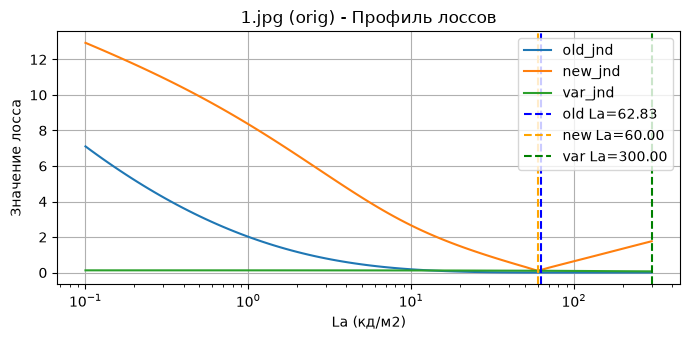

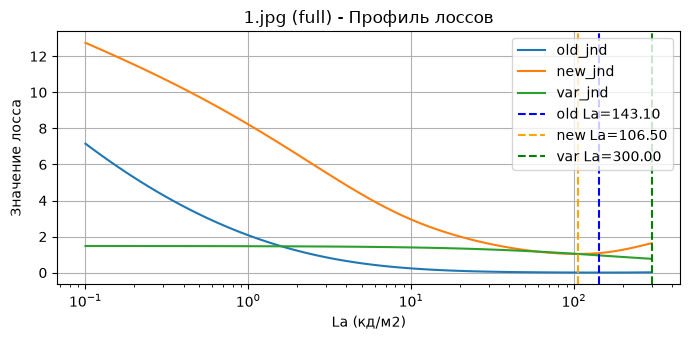

[1/7] Файл: 1.jpg | Средняя яркость L: 108.7321 кд/м2


,model,mode,La,num_levels,mean_jnd_step,mean_delta_L1,rms_delta_L2,max_delta_Linf
0,old_jnd,orig,62.8251,15,37.0650,9.1767,12.2329,36.1421
1,new_jnd,orig,60.0000,44,14.9048,3.6949,5.1733,20.0585
2,var_jnd,orig,299.9998,33,14.7626,3.6788,5.0325,18.5084
3,old_jnd,full,143.1034,14,39.8402,9.9906,13.0737,37.1652
4,new_jnd,full,106.4952,41,13.8449,3.4388,4.7342,17.8207
5,var_jnd,full,299.9998,33,14.7626,3.6788,5.0325,18.5084


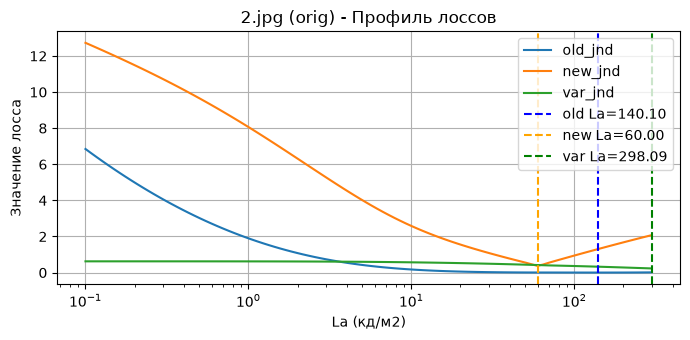

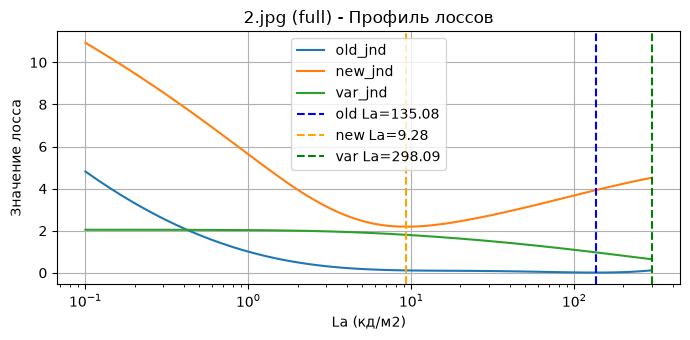

[2/7] Файл: 2.jpg | Средняя яркость L: 21.4713 кд/м2


,model,mode,La,num_levels,mean_jnd_step,mean_delta_L1,rms_delta_L2,max_delta_Linf
0,old_jnd,orig,140.1001,14,10.3485,2.5359,4.5778,36.4170
1,new_jnd,orig,60.0000,44,3.0401,0.7594,1.5106,20.0355
2,var_jnd,orig,298.0915,33,3.5198,0.8793,1.5573,18.2726
3,old_jnd,full,135.0759,14,10.2833,2.5031,4.4935,35.1730
4,new_jnd,full,9.2819,26,6.5564,1.6056,3.3367,33.3251
5,var_jnd,full,298.0915,33,3.5198,0.8793,1.5573,18.2726


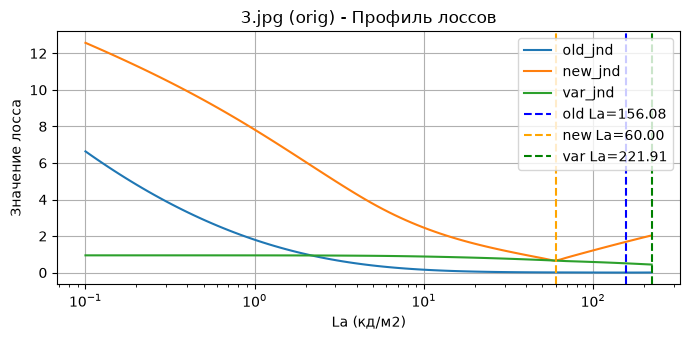

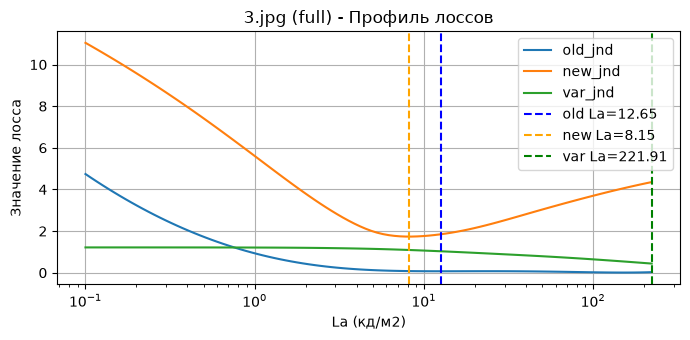

[3/7] Файл: 3.jpg | Средняя яркость L: 14.5265 кд/м2


,model,mode,La,num_levels,mean_jnd_step,mean_delta_L1,rms_delta_L2,max_delta_Linf
0,old_jnd,orig,156.0845,14,7.7751,1.8770,3.0739,28.6335
1,new_jnd,orig,60.0000,44,2.1233,0.5293,0.9197,14.6009
2,var_jnd,orig,221.9109,35,2.4292,0.6053,0.9711,13.6931
3,old_jnd,full,12.6483,16,6.8833,1.6681,2.8771,46.1563
4,new_jnd,full,8.1537,23,5.0098,1.2178,2.2448,36.0210
5,var_jnd,full,221.9109,35,2.4292,0.6053,0.9711,13.6931


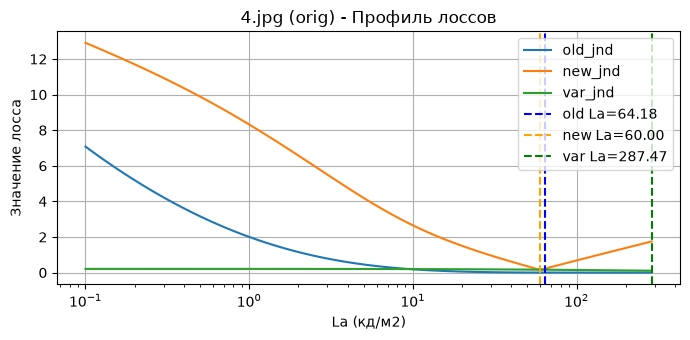

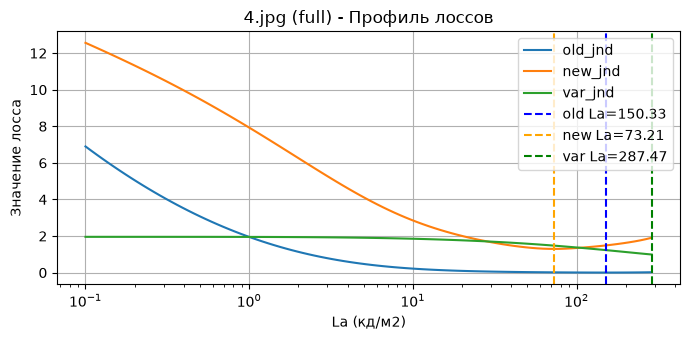

[4/7] Файл: 4.jpg | Средняя яркость L: 100.3806 кд/м2


,model,mode,La,num_levels,mean_jnd_step,mean_delta_L1,rms_delta_L2,max_delta_Linf
0,old_jnd,orig,64.1822,15,32.6159,8.1310,11.3956,36.8222
1,new_jnd,orig,60.0000,44,13.9106,3.4312,5.1529,19.7311
2,var_jnd,orig,287.4651,33,13.6842,3.5186,5.2253,17.7638
3,old_jnd,full,150.3318,14,37.6304,9.9307,13.6346,38.9592
4,new_jnd,full,73.2147,43,13.3508,3.2560,4.8786,17.2701
5,var_jnd,full,287.4651,33,13.6842,3.5186,5.2253,17.7638


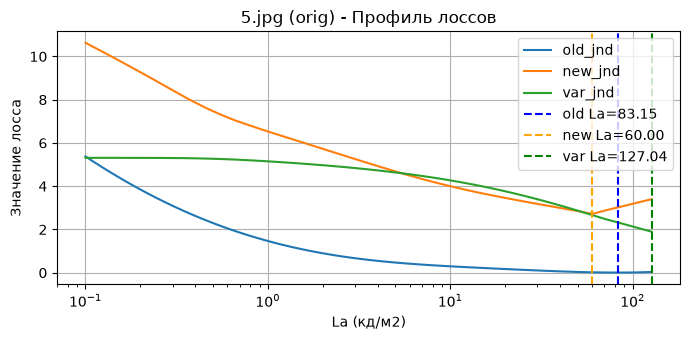

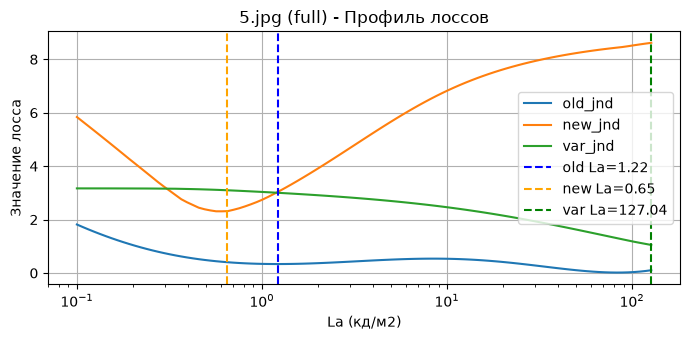

[5/7] Файл: 5.jpg | Средняя яркость L: 9.1554 кд/м2


,model,mode,La,num_levels,mean_jnd_step,mean_delta_L1,rms_delta_L2,max_delta_Linf
0,old_jnd,orig,83.1453,14,3.9655,0.9659,2.3840,15.2554
1,new_jnd,orig,60.0000,44,1.3460,0.3374,1.0018,7.9465
2,var_jnd,orig,127.0379,39,1.5028,0.4735,1.2985,7.9510
3,old_jnd,full,1.2157,10,8.2541,3.3886,10.0035,36.9536
4,new_jnd,full,0.6462,4,36.5713,6.7822,20.8917,108.8811
5,var_jnd,full,127.0379,39,1.5028,0.4735,1.2985,7.9510


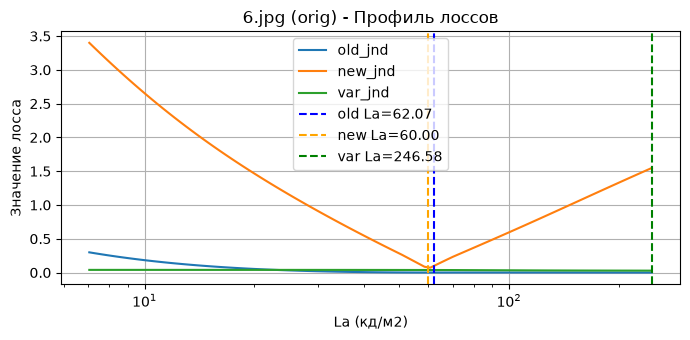

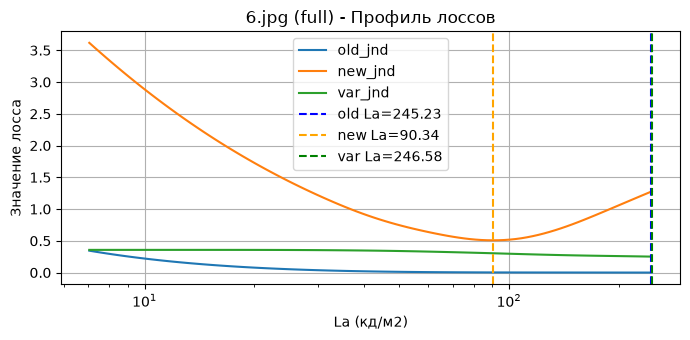

[6/7] Файл: 6.jpg | Средняя яркость L: 89.3720 кд/м2


,model,mode,La,num_levels,mean_jnd_step,mean_delta_L1,rms_delta_L2,max_delta_Linf
0,old_jnd,orig,62.0734,15,32.0091,7.9642,9.8238,35.7279
1,new_jnd,orig,60.0000,44,11.9325,2.9894,3.7879,14.5554
2,var_jnd,orig,246.5803,34,12.1682,3.0429,3.8231,15.2945
3,old_jnd,full,245.2304,12,41.7001,10.1059,12.6210,44.3339
4,new_jnd,full,90.3418,42,11.5369,2.8962,3.6279,14.8924
5,var_jnd,full,246.5803,34,12.1682,3.0429,3.8231,15.2945


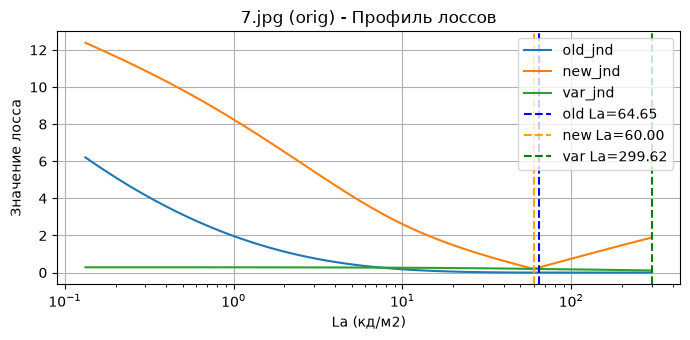

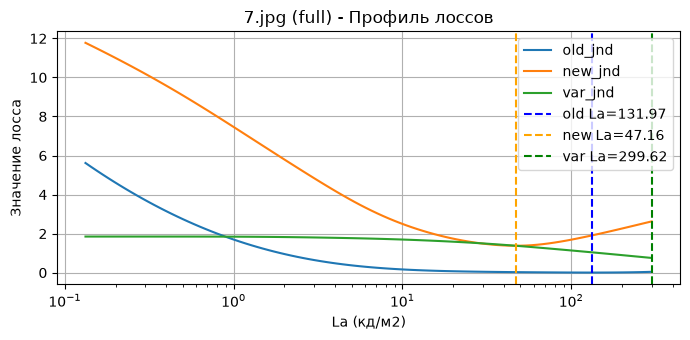

[7/7] Файл: 7.jpg | Средняя яркость L: 57.4090 кд/м2


,model,mode,La,num_levels,mean_jnd_step,mean_delta_L1,rms_delta_L2,max_delta_Linf
0,old_jnd,orig,64.6452,15,22.1298,5.5196,7.9108,37.0498
1,new_jnd,orig,60.0000,44,7.8382,1.9591,3.0353,20.0375
2,var_jnd,orig,299.6157,33,8.1560,2.0337,3.0157,18.4904
3,old_jnd,full,131.9690,14,24.4210,6.0344,8.5305,34.4026
4,new_jnd,full,47.1600,44,7.9736,1.9786,3.0591,19.9373
5,var_jnd,full,299.6157,33,8.1560,2.0337,3.0157,18.4904


In [7]:
import os
import glob
import math
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def compute_screen_geometry_extended(
    patch_shape: tuple[int, int],
    mode: str,
    ppi: float,
    screen_w: int,
    screen_h: int,
    phi_screen: float
) -> tuple[float, int, int, int]:
    h_patch, w_patch = patch_shape
    n_patch = h_patch * w_patch

    if mode == 'full':
        return phi_screen, n_patch, n_patch, 0

    n_total = screen_w * screen_h

    if mode == 'orig':
        n_patch_screen = n_patch
        n_bg = n_total - n_patch_screen
        return phi_screen, n_total, n_patch_screen, n_bg

    if mode == 'scale_15cm':
        target_size_cm = 15.0
        target_max_px = int(np.round((target_size_cm / 2.54) * ppi))
        scale = target_max_px / max(h_patch, w_patch)
        
        target_w_px = int(np.round(w_patch * scale))
        target_h_px = int(np.round(h_patch * scale))
        
        n_patch_screen = target_w_px * target_h_px
        n_bg = n_total - n_patch_screen
        phi = scale * phi_screen
        return phi, n_total, n_patch_screen, n_bg

    raise ValueError(f"Неизвестный режим: {mode}")

def compute_perturbation_metrics_extended(l_matrix: np.ndarray, bounds: np.ndarray) -> dict:
    idx = np.searchsorted(bounds, l_matrix, side='right') - 1
    idx = np.clip(idx, 0, len(bounds) - 2)

    lower_bound = bounds[idx]
    upper_bound = bounds[idx + 1]

    delta_down = l_matrix - lower_bound
    delta_up = upper_bound - l_matrix
    delta_max = np.minimum(delta_down, delta_up)
    delta_max = np.maximum(delta_max, 0.0)

    jnd_steps = upper_bound - lower_bound

    delta_flat = delta_max.ravel()
    l1_mean = float(np.mean(delta_flat))
    l2_rms = float(np.sqrt(np.mean(delta_flat ** 2)))
    linf_max = float(np.max(delta_flat))

    return {
        "num_levels": len(bounds),
        "mean_jnd_step": float(np.mean(jnd_steps)),
        "mean_delta_L1": l1_mean,
        "rms_delta_L2": l2_rms,
        "max_delta_Linf": linf_max
    }

images_folder = "../examples"
valid_extensions = ("*.jpg", "*.jpeg", "*.png")
image_paths = []
for ext in valid_extensions:
    image_paths.extend(glob.glob(os.path.join(images_folder, ext)))
image_paths = sorted(image_paths)[:10]

converter = ImageConverter(L_MIN=0.1, L_MAX=300.0)
modes = ['orig', 'full']
all_results = []

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', '{:.4f}'.format)

for img_idx, img_path in enumerate(image_paths, 1):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        continue

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    xyzL = converter.RGB_to_xyzL(img_rgb)
    l_physical = xyzL[..., 3]
    mean_orig_luminance = float(np.mean(l_physical))
    img_name = os.path.basename(img_path)

    image_results = []

    for mode in modes:
        phi, n_total, n_patch_screen, n_bg = compute_screen_geometry_extended(
            patch_shape=l_physical.shape,
            mode=mode,
            ppi=137.68,
            screen_w=1920,
            screen_h=1080,
            phi_screen=0.0003689
        )

        # 1. old_jnd
        m1 = SimkinJNDModel(
            L_MIN=0.1, L_MAX=300.0, screen_diag_inch=16.0,
            screen_width_px=1920, screen_height_px=1080, distance_m=0.5, l_gray=60.0
        )
        m1.phi = phi
        bounds_m1 = m1._get_search_bounds(l_physical, has_background=(n_bg > 0))
        loss_fn_old = m1._build_loss_func(l_physical, n_total, n_patch_screen, n_bg, loss_mode='square')
        opt_res1 = m1._run_optimizer(
            loss_func=loss_fn_old,
            bounds=bounds_m1,
            optimizer='oscillating_optimizer',
            step=0.1,
            max_reversals=4
        )
        bounds1 = m1.build_level_boundaries()
        metrics1 = compute_perturbation_metrics_extended(l_physical, bounds1)

        row_m1 = {
            "model": "old_jnd",
            "mode": mode,
            "La": opt_res1.La,
            **metrics1
        }
        image_results.append(row_m1)
        all_results.append({"image": img_name, "mean_L_image": mean_orig_luminance, **row_m1})

        # 2. new_jnd
        m2 = HistogramAdaptationJNDModel(
            exposure_time=1.0,
            angular_size_rad=phi,
            detection_probability=0.75,
            l_min=0.1,
            l_max=300.0,
            screen_width_px=1920,
            screen_height_px=1080,
            l_gray=60.0
        )
        flat_l = np.maximum(l_physical.ravel(), m2.luminance_floor)
        u_l, counts = np.unique(flat_l, return_counts=True)
        probs = (counts / l_physical.size) * (n_patch_screen / n_total)
        if n_bg > 0:
            u_l = np.append(u_l, m2.l_gray)
            probs = np.append(probs, n_bg / n_total)
        l_hist, p_hist = m2.prepare_histogram(u_l, probs)
        
        res_m2 = m2.fit(l_hist, p_hist)
        m2.la = res_m2.La
        bounds2 = m2.build_level_boundaries()
        metrics2 = compute_perturbation_metrics_extended(l_physical, bounds2)

        row_m2 = {
            "model": "new_jnd",
            "mode": mode,
            "La": m2.la,
            **metrics2
        }
        image_results.append(row_m2)
        all_results.append({"image": img_name, "mean_L_image": mean_orig_luminance, **row_m2})

        # 3. var_jnd
        m3 = VarJNDModel(
            exposure_time=1.0,
            angular_size_rad=phi,
            detection_probability=0.75,
            l_min=0.1,
            l_max=300.0,
            screen_width_px=1920,
            screen_height_px=1080,
            l_gray=60.0
        )
        lower_v = max(float(l_hist.min()), m3.luminance_floor)
        upper_v = float(l_hist.max())
        if lower_v >= upper_v:
            lower_v = max(lower_v / 2.0, m3.luminance_floor)
            upper_v = upper_v * 2.0

        def obj_var(log_la_val):
            curr_la = math.exp(float(log_la_val))
            d_vals = m3.D(l_hist, curr_la)
            log_sens = -np.log(np.maximum(d_vals, 1e-12))
            mean_sens = float(np.sum(p_hist * log_sens))
            return float(np.sum(p_hist * ((log_sens - mean_sens) ** 2)))

        res_m3 = minimize_scalar(
            obj_var,
            bounds=(math.log(lower_v), math.log(upper_v)),
            method='bounded',
            options={'xatol': 1e-6}
        )
        m3.la = math.exp(float(res_m3.x))
        bounds3 = m3.build_level_boundaries()
        metrics3 = compute_perturbation_metrics_extended(l_physical, bounds3)

        row_m3 = {
            "model": "var_jnd",
            "mode": mode,
            "La": m3.la,
            **metrics3
        }
        image_results.append(row_m3)
        all_results.append({"image": img_name, "mean_L_image": mean_orig_luminance, **row_m3})

        # График профилей лоссов
        la_grid = np.geomspace(math.exp(bounds_m1[0]), math.exp(bounds_m1[1]), 100)
        losses_old = [loss_fn_old(math.log(v)) for v in la_grid]
        losses_new = [m2.loss(v, l_hist, p_hist) for v in la_grid]
        losses_var = [obj_var(math.log(v)) for v in la_grid]

        plt.figure(figsize=(7, 3.5))
        plt.semilogx(la_grid, losses_old, label='old_jnd')
        plt.semilogx(la_grid, losses_new, label='new_jnd')
        plt.semilogx(la_grid, losses_var, label='var_jnd')
        plt.axvline(opt_res1.La, linestyle='--', color='blue', label=f'old La={opt_res1.La:.2f}')
        plt.axvline(m2.la, linestyle='--', color='orange', label=f'new La={m2.la:.2f}')
        plt.axvline(m3.la, linestyle='--', color='green', label=f'var La={m3.la:.2f}')
        plt.title(f'{img_name} ({mode}) - Профиль лоссов')
        plt.xlabel('La (кд/м2)')
        plt.ylabel('Значение лосса')
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

    df_img = pd.DataFrame(image_results)
    print(f"[{img_idx}/{len(image_paths)}] Файл: {img_name} | Средняя яркость L: {mean_orig_luminance:.4f} кд/м2")
    display(df_img)

df_results = pd.DataFrame(all_results)

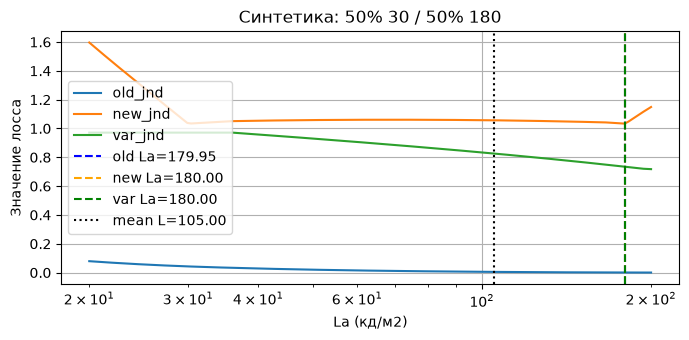

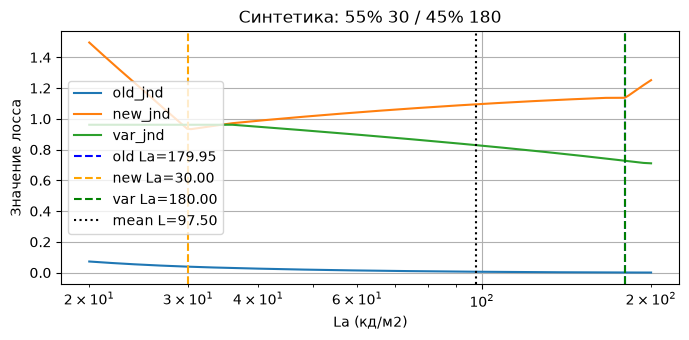

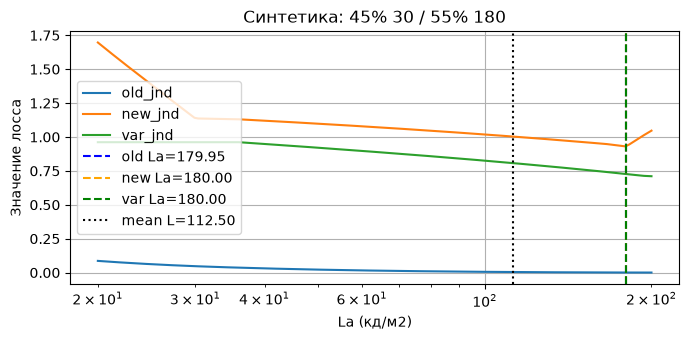

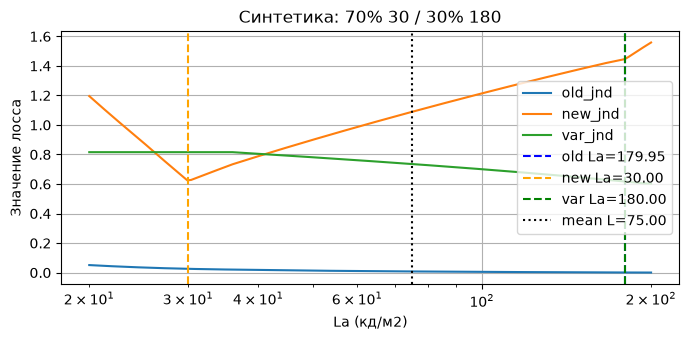

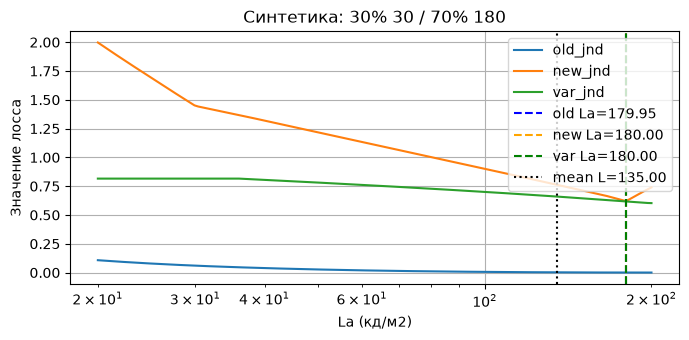

,distribution,mean_L,model,La,num_levels,mean_jnd_step,mean_delta_L1,rms_delta_L2,max_delta_Linf
0,50% 30 / 50% 180,105.0000,old_jnd,179.9459,13,41.5298,0.9290,1.2761,1.8039
1,50% 30 / 50% 180,105.0000,new_jnd,179.9999,37,13.3357,0.2302,0.3255,0.4603
2,50% 30 / 50% 180,105.0000,var_jnd,179.9999,37,13.3357,0.2302,0.3255,0.4603
3,55% 30 / 45% 180,97.5000,old_jnd,179.9459,13,39.1135,1.0165,1.3383,1.8039
4,55% 30 / 45% 180,97.5000,new_jnd,30.0000,44,14.6383,0.5359,0.7989,1.1909
5,55% 30 / 45% 180,97.5000,var_jnd,179.9999,37,12.4141,0.2532,0.3414,0.4603
6,45% 30 / 55% 180,112.5000,old_jnd,179.9459,13,43.9461,0.8415,1.2108,1.8039
7,45% 30 / 55% 180,112.5000,new_jnd,179.9999,37,14.2573,0.2072,0.3088,0.4603
8,45% 30 / 55% 180,112.5000,var_jnd,179.9999,37,14.2573,0.2072,0.3088,0.4603
9,70% 30 / 30% 180,75.0000,old_jnd,179.9459,13,31.8646,1.2790,1.5095,1.8039


In [8]:
m1 = SimkinJNDModel(L_MIN=0.1, L_MAX=300.0, screen_diag_inch=16.0, screen_width_px=1920, screen_height_px=1080, distance_m=0.5, l_gray=60.0)

m2 = HistogramAdaptationJNDModel(
    exposure_time=1.0,
    angular_size_rad=m1.phi_screen,
    detection_probability=0.75,
    l_min=0.1,
    l_max=300.0,
    screen_width_px=1920,
    screen_height_px=1080,
    l_gray=60.0
)

m3 = VarJNDModel(
    exposure_time=1.0,
    angular_size_rad=m1.phi_screen,
    detection_probability=0.75,
    l_min=0.1,
    l_max=300.0,
    screen_width_px=1920,
    screen_height_px=1080,
    l_gray=60.0
)

# Проверяемые соотношения (вес_30, вес_180)
experiments = [
    (0.50, 0.50, "50% 30 / 50% 180"),
    (0.55, 0.45, "55% 30 / 45% 180"),
    (0.45, 0.55, "45% 30 / 55% 180"),
    (0.70, 0.30, "70% 30 / 30% 180"),
    (0.30, 0.70, "30% 30 / 70% 180")
]

synth_results = []
h_px, w_px = 100, 100
total_px = h_px * w_px

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', '{:.4f}'.format)

for p1, p2, label in experiments:
    # Генерируем массив пикселей
    n1 = int(round(total_px * p1))
    n2 = total_px - n1
    patch = np.array([30.0] * n1 + [180.0] * n2, dtype=np.float64).reshape(h_px, w_px)
    mean_L = 30.0 * p1 + 180.0 * p2

    # 1. old_jnd
    opt_res1 = m1.find_La(
        L_patch=patch,
        target_width='full',
        optimizer='oscillating_optimizer',
        loss_mode='square',
        step=0.1,
        max_reversals=4
    )
    bounds1 = m1.build_level_boundaries()
    metrics1 = compute_perturbation_metrics_extended(patch, bounds1)

    synth_results.append({
        "distribution": label,
        "mean_L": mean_L,
        "model": "old_jnd",
        "La": opt_res1.La,
        **metrics1
    })

    # 2. new_jnd
    L_hist = np.array([30.0, 180.0])
    p_hist = np.array([p1, p2])
    res_m2 = m2.fit(L_hist, p_hist)
    m2.la = res_m2.La
    bounds2 = m2.build_level_boundaries()
    metrics2 = compute_perturbation_metrics_extended(patch, bounds2)

    synth_results.append({
        "distribution": label,
        "mean_L": mean_L,
        "model": "new_jnd",
        "La": m2.la,
        **metrics2
    })

    # 3. var_jnd
    def obj_var(log_la_val):
        curr_la = math.exp(float(log_la_val))
        d_vals = m3.D(L_hist, curr_la)
        log_sens = -np.log(np.maximum(d_vals, 1e-12))
        mean_sens = float(np.sum(p_hist * log_sens))
        return float(np.sum(p_hist * ((log_sens - mean_sens) ** 2)))

    res_m3 = minimize_scalar(
        obj_var,
        bounds=(math.log(30.0), math.log(180.0)),
        method='bounded',
        options={'xatol': 1e-6}
    )
    m3.la = math.exp(float(res_m3.x))
    bounds3 = m3.build_level_boundaries()
    metrics3 = compute_perturbation_metrics_extended(patch, bounds3)

    synth_results.append({
        "distribution": label,
        "mean_L": mean_L,
        "model": "var_jnd",
        "La": m3.la,
        **metrics3
    })

    # Профиль лоссов для текущего соотношения
    la_grid = np.geomspace(20.0, 200.0, 150)
    
    # Loss для old_jnd
    loss_fn_old = m1._build_loss_func(patch, total_px, total_px, 0, loss_mode='square')
    losses_old = [loss_fn_old(math.log(v)) for v in la_grid]
    losses_new = [m2.loss(v, L_hist, p_hist) for v in la_grid]
    losses_var = [obj_var(math.log(v)) for v in la_grid]

    plt.figure(figsize=(7, 3.5))
    plt.semilogx(la_grid, losses_old, label='old_jnd')
    plt.semilogx(la_grid, losses_new, label='new_jnd')
    plt.semilogx(la_grid, losses_var, label='var_jnd')
    plt.axvline(opt_res1.La, linestyle='--', color='blue', label=f'old La={opt_res1.La:.2f}')
    plt.axvline(m2.la, linestyle='--', color='orange', label=f'new La={m2.la:.2f}')
    plt.axvline(m3.la, linestyle='--', color='green', label=f'var La={m3.la:.2f}')
    plt.axvline(mean_L, linestyle=':', color='black', label=f'mean L={mean_L:.2f}')
    plt.title(f'Синтетика: {label}')
    plt.xlabel('La (кд/м2)')
    plt.ylabel('Значение лосса')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Итоговая сводка
df_synth = pd.DataFrame(synth_results)
display(df_synth)